# 7 · Latent variables, VAEs, GANs, and flows

**Question.** What alternatives to sequential factorization can represent a complex distribution?

[Download the executed notebook](https://chikuang.github.io/teaching/genai/notebooks/07-latent-variable-models.ipynb)

**Python support:** Review [A.5–A.7: tensors, classes and updates](https://chikuang.github.io/teaching/genai/appendices/a-python-pytorch.html#a-5-tensors-and-one-derivative). These chapters form the optional generative-model/adaptation branch after Chapter 6. Use **Show all code** while working.


A latent-variable model generates an unobserved $Z$ and then generates $X$ conditional on it. This connects directly to mixture models and random-effects models. The difficulty is often integrating over $Z$. We will derive a variational objective, train a small variational autoencoder (VAE) on two-dimensional observations, and contrast its objective with adversarial learning and invertible transformations.

**Prerequisites:** Chapters 1–2, conditional densities, Jensen's inequality, and KL divergence. **Outcomes:** distinguish prior, posterior approximation, and observation model; derive the ELBO; implement reparameterization; compare what a VAE, GAN, and flow can evaluate. The VAE is a small CPU experiment; GANs and flows are comparison topics with an exact change-of-variables calculation.

## Pipeline and framework

![The VAE optimizes an encoder-decoder ELBO, the GAN alternates discriminator and generator updates, and a flow uses an invertible map with a Jacobian to evaluate densities. Remember: VAE encodes; GAN competes; flow reverses.](https://chikuang.github.io/teaching/genai/_static/diagrams/07-generative-families.png)

These are **alternative generative frameworks**, not consecutive stages of one model. Start by asking which quantities can be evaluated and which can only be sampled. That determines both the objective and the diagnostics available to you.


| Model | Training route | Generation route | Main diagnostic |
|:--|:--|:--|:--|
| VAE | Encode observed $x$, sample a reparameterized latent, decode, and optimize reconstruction plus KL terms. | Draw $z$ from the prior, then $x$ from the decoder likelihood. | Inspect both ELBO terms and prior-generated samples. |
| GAN | Compare real data with generator samples; alternate discriminator and generator updates. | Draw noise and apply the generator. | Check sample diversity and fidelity; discriminator loss alone is insufficient. |
| Flow | Map between observations and base variables; include the log absolute Jacobian determinant. | Draw a base variable and apply the forward map. | Check invertibility, density normalization where tractable, and held-out likelihood. |

For the VAE code below, the encoder is used during fitting and reconstruction, but it is not needed to generate from the prior. Drawing encoder latents from training observations answers a reconstruction question. Drawing prior latents answers a model-generation question. The GAN section explains the framework conceptually; the executable density check is an affine flow, not a trained neural flow.

## 7.1 · Three distributions with different jobs

Specify a prior $p(z)$ and an observation model $p_\theta(x\mid z)$. The marginal density is $p_\theta(x)=\int p_\theta(x\mid z)p(z)\,dz$. An encoder $q_\phi(z\mid x)$ approximates the posterior. It is not the generative prior.

At training time the encoder uses observed $x$. At unconditional generation time, draw $z\sim p(z)$ and then $x\sim p_\theta(x\mid z)$. Feeding observed data through the encoder and decoder produces a reconstruction, which answers a different question from generating new observations.

## 7.2 · Derive the evidence lower bound

For any suitable density $q_\phi(z\mid x)$,

$$
\begin{aligned}
\log p_\theta(x)
&=\log\mathbb E_{q_\phi}\left[\frac{p_\theta(x,z)}{q_\phi(z\mid x)}\right]\\
&\ge \mathbb E_{q_\phi}\log p_\theta(x\mid z)
 -\operatorname{KL}\{q_\phi(z\mid x)\Vert p(z)\}
 =\mathcal L(\theta,\phi;x).
\end{aligned}
$$

The gap in Equation [(7.1)](https://chikuang.github.io/teaching/genai/chapters/07-latent-variable-models.html#equation-eq-elbo) is $\operatorname{KL}\{q_\phi(z\mid x)\Vert p_\theta(z\mid x)\}\ge0$. Thus improving the bound can involve both improving the marginal model and making the approximate posterior closer to the exact posterior. An expressive decoder does not automatically make the bound tight.

For a diagonal Gaussian encoder and a standard normal prior,

$$
\operatorname{KL}\{N(\mu,\operatorname{diag}(e^\ell))\Vert N(0,I)\}
=\frac12\sum_j(\mu_j^2+e^{\ell_j}-1-\ell_j).
$$

Here $\ell$ is log variance, not log standard deviation. With $p_\theta(x\mid z)=N(f_\theta(z),\sigma_x^2I)$, the reconstruction contribution to negative ELBO, up to a fixed constant, is $\|x-f_\theta(z)\|^2/(2\sigma_x^2)$. Changing this scale changes the observation model and the balance with KL; it is not a harmless numerical adjustment.

## 7.3 · Reparameterize the random draw

Write $z=\mu_\phi(x)+\exp(\ell_\phi(x)/2)\odot\epsilon$ with $\epsilon\sim N(0,I)$. The random variable now has a parameter-free distribution, while the transformation is differentiable in the encoder parameters. This gives a pathwise gradient estimator under the usual interchange conditions.

In [1]:
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.set_num_threads(1)
torch.manual_seed(7)
rng = np.random.default_rng(7)
centers = np.array([[-1., -1.], [-1., 1.], [1., -1.], [1., 1.]])
labels = rng.integers(0, 4, size=1600)
X = centers[labels] + rng.normal(scale=0.18, size=(1600, 2))
train = torch.tensor(X[:1200], dtype=torch.float32)
valid = torch.tensor(X[1200:], dtype=torch.float32)

class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(2, 32), nn.Tanh(), nn.Linear(32, 4))
        self.decoder = nn.Sequential(nn.Linear(2, 32), nn.Tanh(), nn.Linear(32, 2))

    def encode(self, x):
        mu, logvar = self.encoder(x).chunk(2, dim=-1)
        return mu, logvar.clamp(-8, 5)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
        return self.decoder(z), mu, logvar

model = VAE()
observation_sd = 0.18

def loss_parts(x):
    mean, mu, logvar = model(x)
    reconstruction = ((x - mean)**2).sum(-1) / (2 * observation_sd**2)
    kl = 0.5 * (mu**2 + logvar.exp() - 1 - logvar).sum(-1)
    return reconstruction.mean(), kl.mean()

zero = torch.zeros(3, 2)
assert torch.allclose(0.5*(zero**2 + zero.exp()-1-zero).sum(-1), torch.zeros(3))

Clamping log variance limits extreme values in this small experiment and is part of the chosen encoder family. The first 1,200 observations are training data and the remaining 400 are validation data from the same simulated mixture. We use a fixed training budget; validation is a diagnostic rather than a source of repeated hyperparameter searches.

### The loss actually estimated by a minibatch

For $x_i\in\mathbb R^{d_x}$ and $z_i\in\mathbb R^{d_z}$, let $g_\phi(x_i,\epsilon_i)=\mu_\phi(x_i)+\exp(\ell_\phi(x_i)/2)\odot\epsilon_i$. With independent $\epsilon_i\sim N(0,I_{d_z})$, the code uses one latent draw per observation to estimate

$$
\widehat J=\frac1m\sum_{i=1}^m\left[
\frac{\|x_i-f_\theta(g_\phi(x_i,\epsilon_i))\|_2^2}{2\sigma_x^2}
+\frac12\sum_{j=1}^{d_z}
\{\mu_{ij}^2+e^{\ell_{ij}}-1-\ell_{ij}\}\right].
$$

Equation [(7.3)](https://chikuang.github.io/teaching/genai/chapters/07-latent-variable-models.html#equation-eq-vae-loss) combines a sampled reconstruction term from Equation [(7.1)](https://chikuang.github.io/teaching/genai/chapters/07-latent-variable-models.html#equation-eq-elbo) with the analytic Gaussian KL in Equation [(7.2)](https://chikuang.github.io/teaching/genai/chapters/07-latent-variable-models.html#equation-eq-gaussian-kl). Its inner sums run over coordinates, and the outer mean runs over observations. Here $d_x=d_z=2$ and $\sigma_x=0.18$. The omitted negative-log-Gaussian constant is $d_x\log(2\pi\sigma_x^2)/2$ per observation; it is fixed only because the observation variance is fixed. Averaging coordinate errors instead of summing them would change the reconstruction/KL balance.

Under conditions allowing differentiation through the expectation,

$$
\nabla_\phi\mathbb E_{\epsilon}[r_{\theta,\phi}(x,\epsilon)]
=\mathbb E_{\epsilon}[\nabla_\phi r_{\theta,\phi}(x,\epsilon)],
$$

where $r$ is the reconstruction term. Autodiff follows $\epsilon\to z\to f_\theta(z)$ with the sampled $\epsilon$ held fixed; the KL term is differentiated analytically through its closed form. The stochastic estimate of negative ELBO need not itself bound the negative log likelihood for each individual noise draw; the bound concerns its expectation.

> **Example 7.1 · A Gaussian encoder produces a distribution**
>
> **Setup.** For one observed $x$, suppose the encoder gives $q(z\mid x)=N(1,4)$, while the prior is $N(0,1)$. The encoder's log variance is $\log4$.
>
> **Work it through.** With noise draw $\epsilon=-0.5$, reparameterization gives $z=1+2(-0.5)=0$. Equation [(7.2)](https://chikuang.github.io/teaching/genai/chapters/07-latent-variable-models.html#equation-eq-gaussian-kl) gives $\mathrm{KL}(q\Vert p)=\tfrac12(1^2+4-1-\log4)\approx1.3069$. Thus this particular draw lands at the prior mean, even though the encoder distribution differs substantially from the prior. A reconstruction decodes this encoder draw; generating a new observation instead starts with a fresh draw from the prior.
>
> **What this shows.** The KL penalty compares distributions, not the location of one sampled latent value. Reparameterization uses the standard deviation 2, not the variance 4 or the log variance, and preserves a differentiable path through the encoder's parameters.

## 7.4 · Optimize and inspect both objective components

Validation reconstruction / KL: [1.144 2.398]


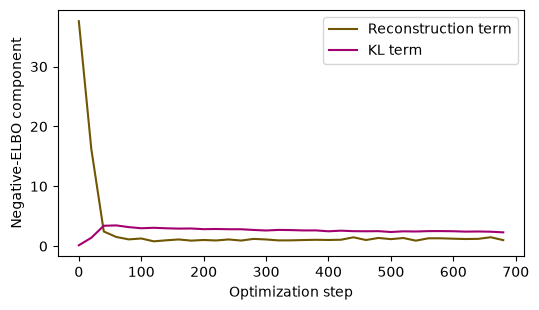

In [2]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.005)
history = []
for step in range(700):
    ids = torch.randint(len(train), (128,))
    optimizer.zero_grad()
    reconstruction, kl = loss_parts(train[ids])
    (reconstruction + kl).backward()
    optimizer.step()
    if step % 20 == 0:
        history.append((step, reconstruction.item(), kl.item()))
model.eval()
with torch.no_grad():
    validation_terms = np.array([[a.item(), b.item()]
                                for a, b in [loss_parts(valid) for _ in range(20)]])
print('Validation reconstruction / KL:', validation_terms.mean(0).round(3))
history = np.asarray(history)
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(history[:, 0], history[:, 1], label='Reconstruction term', color='#705600')
ax.plot(history[:, 0], history[:, 2], label='KL term', color='#a2006e')
ax.set(xlabel='Optimization step', ylabel='Negative-ELBO component')
ax.legend()
plt.tight_layout()
plt.show()

The reported objective is Equation [(7.3)](https://chikuang.github.io/teaching/genai/chapters/07-latent-variable-models.html#equation-eq-vae-loss), which omits the fixed Gaussian normalization constant. It is therefore not an exact negative log likelihood. Repeated validation draws reduce Monte Carlo noise conditional on the fitted model; they do not measure uncertainty from sampling a new training dataset.

A small KL term can mean that the encoder stays close to the prior. If the decoder also ignores $z$, this is posterior collapse. A good reconstruction score alone is insufficient: the prior samples could still occupy regions the decoder handles poorly.

## 7.5 · Generate from the prior, not the encoder

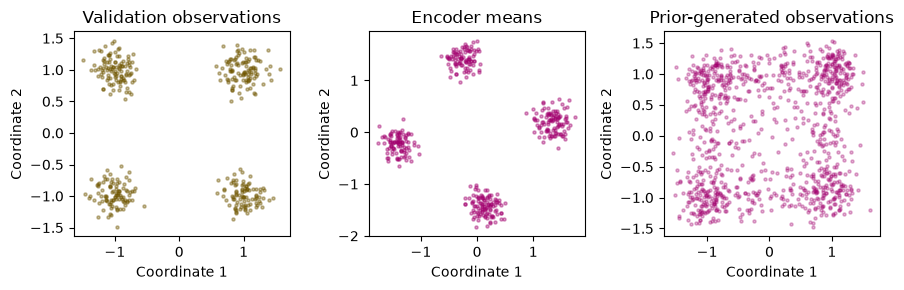

Observed mean: [-0.025  0.067]
Generated mean: [-0.003  0.069]


In [3]:
with torch.no_grad():
    latent_mean, _ = model.encode(valid)
    decoder_mean = model.decoder(torch.randn(1000, 2))
    generated = decoder_mean + observation_sd * torch.randn_like(decoder_mean)
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].scatter(valid[:, 0], valid[:, 1], s=5, alpha=0.4, color='#705600')
axes[1].scatter(latent_mean[:, 0], latent_mean[:, 1], s=5, alpha=0.4, color='#a2006e')
axes[2].scatter(generated[:, 0], generated[:, 1], s=5, alpha=0.3, color='#a2006e')
for ax, title in zip(axes, ['Validation observations', 'Encoder means', 'Prior-generated observations']):
    ax.set(title=title, xlabel='Coordinate 1', ylabel='Coordinate 2')
plt.tight_layout()
plt.show()
print('Observed mean:', valid.mean(0).numpy().round(3))
print('Generated mean:', generated.mean(0).numpy().round(3))

Inspect whether all four clusters appear, whether their spread is appropriate, and whether too much probability lies between clusters. Matching the mean is weak evidence: a single central Gaussian can have the same mean as a separated mixture. A stronger assessment compares several predefined features on held-out observations and generated samples, while recognizing that a finite set of summaries cannot establish equality of distributions.

## 7.6 · GANs: learn through a discrimination problem

A generative adversarial network maps a simple random input through $G_\theta$ and trains a discriminator $D_\psi$ to separate observed from generated samples. The original minimax objective is

$$
\min_\theta\max_\psi\left[
\mathbb E_{P_0}\log D_\psi(X)
+\mathbb E_Z\log\{1-D_\psi(G_\theta(Z))\}\right].
$$

For fixed distributions and an unrestricted optimal discriminator, $D^*(x)=p_0(x)/(p_0(x)+p_G(x))$ where the density expression is defined. This motivates a density-ratio interpretation, but practical networks and alternating optimization do not achieve that ideal automatically. Mode collapse means the generator can neglect portions of the target distribution. Unlike our VAE observation model, a general GAN does not supply a tractable density for an arbitrary observation.

A commonly used generator update instead minimizes the **non-saturating** loss

$$
L_G^{\mathrm{NS}}(\theta)=-\mathbb E_{Z\sim p_Z}\log D_\psi(G_\theta(Z)),
$$

holding $\psi$ fixed during that update. It encourages generated samples to receive large discriminator scores, but it has a different gradient from the generator term of Equation [(7.4)](https://chikuang.github.io/teaching/genai/chapters/07-latent-variable-models.html#equation-eq-gan-minimax), namely $\mathbb E_Z\log(1-D_\psi(G_\theta(Z)))$. The discriminator output is a real-versus-generated classification score under its training mixture, not a calibrated probability that a sample is scientifically valid. This chapter explains the objectives; it does not execute GAN training.

## 7.7 · Flows: retain an invertible map and its Jacobian

For an invertible differentiable map $x=f_\theta(z)$ of equal-dimensional spaces,

$$
\log p_X(x)=\log p_Z(f_\theta^{-1}(x))
-\log|\det J_{f_\theta}(f_\theta^{-1}(x))|.
$$

Writing $g_\theta=f_\theta^{-1}$ makes the equivalent inverse-map formula and fitting objective explicit:

$$
\log p_X(x)=\log p_Z(g_\theta(x))+\log|\det J_{g_\theta}(x)|,
\qquad \widehat L_{\mathrm{flow}}=-\frac1N\sum_{i=1}^N\log p_X(x_i).
$$

Relative to Equation [(7.5)](https://chikuang.github.io/teaching/genai/chapters/07-latent-variable-models.html#equation-eq-flow-density), the sign changes because the inverse Jacobian determinant is the reciprocal of the forward determinant. The identity assumes an invertible differentiable map with a nonzero Jacobian determinant at the evaluated points. Both maps act on the same dimension; the encoder of a general VAE has no such invertibility requirement.

Consider the one-dimensional affine flow $X=aZ+b$, $a>0$. Its density is exactly a normal density with mean $b$ and standard deviation $a$.

In [4]:
a, b = 1.7, -0.4
x = np.linspace(-4, 4, 100)
z = (x - b) / a
flow_log_density = -0.5*z*z - 0.5*np.log(2*np.pi) - np.log(a)
direct_log_density = -0.5*((x-b)/a)**2 - np.log(a*np.sqrt(2*np.pi))
assert np.allclose(flow_log_density, direct_log_density)
print('Change-of-variables identity verified.')

Change-of-variables identity verified.


Expressive flows use transformations whose inverse and determinant remain computationally manageable. Invertibility constrains the architecture; it buys exact density evaluation for the specified model, not a guarantee that the model fits the data.

> **Example 7.2 · A flow must account for stretched volume**
>
> **Setup.** Let $Z\sim N(0,1)$ and define the invertible map $X=2Z+1$.
>
> **Work it through.** The inverse is $z=(x-1)/2$, with absolute derivative $1/2$. Equation [(7.5)](https://chikuang.github.io/teaching/genai/chapters/07-latent-variable-models.html#equation-eq-flow-density) therefore gives $p_X(x)=\phi((x-1)/2)/2$, where $\phi$ is the standard normal density. At $x=1$, this is approximately $0.1995$, half of $\phi(0)\approx0.3989$. Dropping the factor $1/2$ would produce a function whose integral is 2 rather than 1.
>
> **What this shows.** The transformation doubles lengths, so the density must halve to preserve probability mass. A flow needs both an inverse and its volume correction. Evaluating the base density at the inverse point alone is not a normalized density for the transformed observation.


### Coding and experiment practice · Choose statistics that distinguish distributions

**1. Predict before running.** Why do a centered spherical Gaussian and the symmetric four-cluster mixture both assign one quarter of their mass to each nearest-center region?

**2. Implement and check.** Compare fitted single-Gaussian and VAE samples under the same 1,000-draw budget. Predeclare radius 0.4. Report region occupancy, nearest-center distance quantiles and mass within that radius. Try your own implementation before expanding the reference code below. Replace the reference function body with your version and rerun the acceptance checks in a fresh kernel.

In [5]:
def distribution_diagnostics(samples, centers, radius=0.4):
    samples = np.asarray(samples)
    distances = np.sqrt(((samples[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2))
    nearest = distances.min(axis=1)
    region = distances.argmin(axis=1)
    return {'occupancy': np.bincount(region, minlength=len(centers)) / len(samples),
            'distance_quantiles': np.quantile(nearest, [0.25, 0.5, 0.75]),
            'near_center_mass': float(np.mean(nearest <= radius))}

at_centers = distribution_diagnostics(centers, centers)
assert np.allclose(at_centers['occupancy'], 0.25)
assert at_centers['near_center_mass'] == 1
assert distribution_diagnostics(np.zeros((4, 2)), centers)['near_center_mass'] == 0
comparison_rng = np.random.default_rng(707)
gaussian_sample = comparison_rng.multivariate_normal(
    train.numpy().mean(0), np.cov(train.numpy(), rowvar=False, bias=True), size=1000)
fresh_target = centers[comparison_rng.integers(0, 4, 1000)] + comparison_rng.normal(0, 0.18, (1000, 2))
for name, sample in [('Fresh target', fresh_target), ('Fitted Gaussian', gaussian_sample),
                     ('Fitted VAE', generated.numpy())]:
    diagnostics = distribution_diagnostics(sample, centers)
    assert len(sample) == 1000 and np.isclose(diagnostics['occupancy'].sum(), 1)
    print(name, {key: np.round(value, 3) for key, value in diagnostics.items()})

Fresh target {'occupancy': array([0.275, 0.227, 0.236, 0.262]), 'distance_quantiles': array([0.138, 0.213, 0.295]), 'near_center_mass': np.float64(0.918)}
Fitted Gaussian {'occupancy': array([0.249, 0.255, 0.221, 0.275]), 'distance_quantiles': array([0.589, 0.827, 1.044]), 'near_center_mass': np.float64(0.106)}
Fitted VAE {'occupancy': array([0.247, 0.255, 0.22 , 0.278]), 'distance_quantiles': array([0.237, 0.39 , 0.685]), 'near_center_mass': np.float64(0.513)}


The three-dimensional distance array has sample, center and coordinate axes before summation. Nearest-center regions here are the four quadrants. Equal occupancy cannot reveal the empty space between modes. Distance and neighborhood mass add sensitivity to that difference; no finite collection of summaries proves equality of distributions. The fresh target is a simulator reference, not extra fitting data.

**3. Extend one factor.** Vary the predeclared radius on a development set, then freeze it before a fresh comparison. Alternatively compare a moment-matched spherical Gaussian with the true mixture to construct an explicit counterexample to occupancy alone.

**Submission and rubric.** Submit the function and its checks, the requested comparison table, and three sentences naming the target, interpreting the result, and limiting the claim. Passing a deterministic fixture verifies the stated calculation; a favorable stochastic result is not required. Retain unexpected results and diagnose them rather than changing seeds until a preferred ranking appears.


## 7.8 · Exercises

1. **ELBO equality:** when is the bound exact?
2. **Log variance:** if `logvar = log(4)`, what multiplier belongs on the standard normal noise?
3. **Generation:** why must observation noise be added to the decoder mean in our VAE?
4. **Model comparison:** which method directly provides exact likelihood, a variational bound, or only a sampling mechanism?
5. **Failure probe:** fit a single Gaussian to the four-cluster data and compare its mean with the VAE.


<details><summary>Worked solutions — attempt the questions first</summary>

**1.** when $q_\phi(z\mid x)$ equals the model posterior almost everywhere. This does not imply that the fitted marginal equals the true data distribution.

**2.** $\exp(\log(4)/2)=2$. Multiplying by four would produce variance 16.

**3.** the decoder parameterizes the mean of a Gaussian observation distribution. Omitting noise samples a different distribution, namely the distribution of conditional means.

**4.** a tractable flow provides exact model likelihood; a VAE provides a computable ELBO and generative model; a standard implicit GAN primarily provides samples. These labels describe objectives and access, not universal quality rankings.

**5.** means may be close for both, while cluster occupancy and density between clusters differ. This demonstrates why evaluation needs more than first moments.

</details>

## 7.9 · Reading and next step

[Auto-Encoding Variational Bayes](https://arxiv.org/abs/1312.6114) develops amortized variational inference and reparameterized optimization. Compare its statistical objects with [Generative Adversarial Nets](https://arxiv.org/abs/1406.2661) and the change-of-variables identity above. [Chapter 8](https://chikuang.github.io/teaching/genai/chapters/08-diffusion.html) turns a sequence of noising and denoising operations into another generative model.